In [18]:
!pip install -q pgmpy

Valid Bayesian Network: True
Independencies: (Fatigue ⟂ Smoking | LungDisease)
(Smoking ⟂ Xray | LungDisease)
(Fatigue ⟂ Pollution | LungDisease)
(Cough ⟂ Smoking | LungDisease)
(Cough ⟂ Pollution | LungDisease)
(Pollution ⟂ Xray | LungDisease)
(Fatigue ⟂ Xray | LungDisease)
(Pollution ⟂ Smoking)
(Cough ⟂ Fatigue | LungDisease)
(Cough ⟂ Xray | LungDisease)


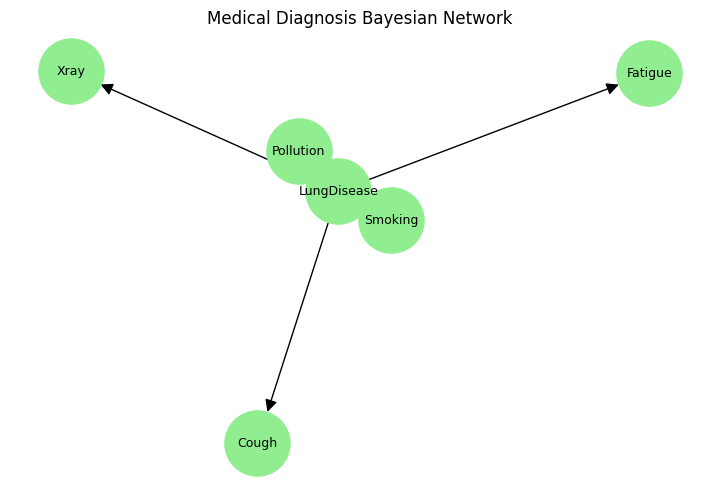

In [19]:
# !pip install -q pgmpy
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

model = DiscreteBayesianNetwork([
    ("Smoking", "LungDisease"),
    ("Pollution", "LungDisease"),
    ("LungDisease", "Cough"),
    ("LungDisease", "Xray"),
    ("LungDisease", "Fatigue"),
])

cpd_smoke = TabularCPD("Smoking", 2, [[0.7], [0.3]])
cpd_poll = TabularCPD("Pollution", 2, [[0.8], [0.2]])
cpd_lung = TabularCPD(
    "LungDisease", 2,
    [[0.98, 0.85, 0.70, 0.20], [0.02, 0.15, 0.30, 0.80]],
    evidence=["Smoking", "Pollution"], evidence_card=[2, 2]
)
cpd_cough = TabularCPD("Cough", 2, [[0.8, 0.2], [0.2, 0.8]], evidence=["LungDisease"], evidence_card=[2])
cpd_xray = TabularCPD("Xray", 2, [[0.9, 0.15], [0.1, 0.85]], evidence=["LungDisease"], evidence_card=[2])
cpd_fat = TabularCPD("Fatigue", 2, [[0.75, 0.3], [0.25, 0.7]], evidence=["LungDisease"], evidence_card=[2])

model.add_cpds(cpd_smoke, cpd_poll, cpd_lung, cpd_cough, cpd_xray, cpd_fat)
print("Valid Bayesian Network:", model.check_model())
print("Independencies:", model.get_independencies())

G = nx.DiGraph(model.edges())
pos = nx.spring_layout(G, seed=42)
plt.figure(figsize=(7, 4.5))
nx.draw(G, pos, with_labels=True, node_color="lightgreen", node_size=2200, font_size=9, arrowsize=18)
plt.title("Medical Diagnosis Bayesian Network"); plt.show()